<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Minería de Datos · Proyecto Final</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Modelo de árboles sobre rasgos de estilo</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Miguel A. Garcia, Nadia Ramos, Ángel J. Zamora</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

Este notebook entrena un Random Forest sobre los 10 rasgos de estilo de `preparacion_datos.ipynb` (no sobre TF-IDF) y lo compara con una regresión logística sobre los mismos rasgos y con el modelo de texto elegido. **Lee** `data/processed/corpus.parquet` y `resultados/seleccion_lineal.json`; **no carga el test**. Escribe `resultados/cv_arboles.csv`, `resultados/seleccion_arboles.json` y figuras en `figuras/`.

## Contenido

    * [Sección 0: Configuración](#seccion-0)
* **[Metodología CRISP-DM: Modelado](#fase-modelado)**
    * [Sección 1: Datos y rasgos](#seccion-1)
    * [Sección 2: Referencia lineal sobre los rasgos](#seccion-2)
    * [Sección 3: Random Forest](#seccion-3)
    * [Sección 4: Importancia de los rasgos](#seccion-4)
    * [Sección 5: Diagnóstico: folds aleatorios](#seccion-5)
    * [Sección 6: Comparación con el modelo de texto](#seccion-6)
    * [Sección 7: Selección y guardado](#seccion-7)
* **[Conclusiones](#conclusiones)**
    * [Sección 8: Resumen por sección](#seccion-8)
    * [Sección 9: Implicaciones para la evaluación](#seccion-9)
    * [Sección 10: Referencias](#seccion-10)

<a id="seccion-0"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 0: Configuración</span></div>

> **Qué se hace:** cargamos bibliotecas y fijamos las rejillas.
>
> **Qué se espera ver:** constantes justificadas antes de ver resultados.

### 0.1 Bibliotecas

In [1]:
# Manejo de datos
import json
import os
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt

# Modelado
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, make_scorer
from sklearn.model_selection import ParameterGrid

# Funciones compartidas del proyecto
import utils_fakedes as uf
from utils_fakedes import guardar, guardar_csv

### 0.2 Constantes y rejillas

| Constante | Valores | Justificación |
|:--|:--|:--|
| `REJILLA_RF['max_depth']` | 3, 5, 8, sin límite | De árboles poco profundos (interpretables, menos sobreajuste) a árboles completos |
| `REJILLA_RF['min_samples_leaf']` | 1, 5, 20 | Hojas de 1 noticia hasta hojas de 20 (≈ 2.5 % del fold de entrenamiento) |
| `REJILLA_RF['max_features']` | `sqrt` (3 de 10), 0.5 (5 de 10) | Más o menos decorrelación entre árboles |
| `N_ARBOLES` | 500 | Suficiente para estabilizar el voto con 10 rasgos; no se ajusta |
| `REJILLA_LR_ESTILO` (C) | 0.01, 0.1, 1, 10 | Regularización fuerte a débil para 10 rasgos escalados |

In [2]:
SEMILLA = uf.SEMILLA
COLORES_CLASE = uf.COLORES_CLASE
TINTA, TINTA_SUAVE = uf.TINTA, uf.TINTA_SUAVE
RASGOS = uf.RASGOS_ESTILO
N_ARBOLES = 500
REJILLA_RF = {'max_depth': [3, 5, 8, None], 'min_samples_leaf': [1, 5, 20], 'max_features': ['sqrt', 0.5]}
REJILLA_LR_ESTILO = [0.01, 0.1, 1, 10]
F1_FAKE = make_scorer(f1_score, pos_label = 'Fake')
uf.configurar_graficas()

### 0.3 Rutas

**Tabla 0.3.** Archivos que lee y escribe el notebook.

In [3]:
pd.DataFrame({'archivo': ['data/processed/corpus.parquet', 'resultados/seleccion_lineal.json', 'resultados/cv_arboles.csv', 'resultados/seleccion_arboles.json'],
              'uso': ['lectura: train + development con folds y rasgos', 'lectura: modelo de texto elegido', 'todas las combinaciones por fold', 'configuración elegida']})

,archivo,uso
0,data/processed/corpus.parquet,lectura: train + development con folds y rasgos
1,resultados/seleccion_lineal.json,lectura: modelo de texto elegido
2,resultados/cv_arboles.csv,todas las combinaciones por fold
3,resultados/seleccion_arboles.json,configuración elegida


<a id="fase-modelado"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metodología CRISP-DM: Modelado</span></div>

<a id="seccion-1"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 1: Datos y rasgos</span></div>

> **Qué se hace:** cargamos el corpus preparado y describimos los 10 rasgos por clase.
>
> **Qué se espera ver:** diferencias pequeñas entre clases salvo en longitud y números (preparación de los datos, Tabla 5.2).

⚠️ Los rasgos se calcularon solo con el texto, no con el titular, para que los 72 titulares vacíos del test no den una señal artificial.

**Tabla 1.1.** Mediana de cada rasgo por clase en `train` + `development` (definiciones en `preparacion_datos.ipynb`, Tabla 5.1).

In [4]:
corpus = pd.read_parquet(os.path.join(uf.RUTA_PROCESADOS, 'corpus.parquet'))
assert (corpus['particion'] != 'test').all()
corpus.groupby('Category')[RASGOS].median().T.round(3)

Category,Fake,True
est_log_palabras,5.557,5.911
est_palabras_por_oracion,32.618,29.111
est_long_media_palabra,4.781,4.885
est_prop_mayusculas,0.027,0.034
est_prop_palabras_mayusculas,0.003,0.004
est_exclamaciones,0.000,0.000
est_interrogaciones,0.000,0.000
est_comillas,3.367,2.590
est_numeros,0.436,1.217
est_prop_vacias,0.585,0.560


<a id="seccion-2"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 2: Referencia lineal sobre los rasgos</span></div>

> **Qué se hace:** entrenamos una regresión logística sobre los 10 rasgos escalados para saber cuánto aporta la no linealidad de los árboles.
>
> **Qué se espera ver:** un desempeño claramente menor que el de los modelos de texto.

**Tabla 2.1.** Regresión logística sobre los rasgos escalados (CV agrupada, media ± sd).

In [5]:
def lr_estilo(entrenamiento, validacion):
    '''
    Función que entrena la regresión logística sobre los rasgos para cada valor de C

    inputs:
    --------
        entrenamiento (pandas.DataFrame): Folds de entrenamiento
        validacion (pandas.DataFrame): Fold de validación

    outputs:
    --------
        dict: Predicciones por valor de C
    '''
    return {f'LR C={c}': uf.construir_modelo_estilo({'modelo': 'LR', 'parametros': {'C': c}}).fit(entrenamiento, entrenamiento['Category']).predict(validacion)
            for c in REJILLA_LR_ESTILO}

cv_lr_estilo = uf.evaluar_por_folds(corpus, 'fold_grupo', lr_estilo)
uf.resumir_cv(cv_lr_estilo).round(3)

,F1_fake_mean,F1_fake_std,F1_macro_mean,F1_macro_std,accuracy_mean,accuracy_std,F1_fake_se
config,,,,,,,
LR C=0.01,0.672,0.094,0.691,0.073,0.694,0.071,0.042
LR C=0.1,0.670,0.098,0.692,0.077,0.695,0.075,0.044
LR C=1,0.669,0.086,0.689,0.070,0.692,0.069,0.038
LR C=10,0.668,0.088,0.689,0.072,0.692,0.071,0.039


**Qué se observa.** La regresión logística sobre los 10 rasgos escalados da una F1 de fake de 0.668 a 0.672 en las 4 regularizaciones (sd ≈ 0.09): el valor de C casi no importa. Queda 0.06 por debajo del modelo de texto elegido (0.730) y 0.035 por debajo de la réplica BoW (0.707). **Diez rasgos de forma capturan buena parte de la señal, pero no toda; es la referencia que el bosque debe superar para justificar la no linealidad.**

<a id="seccion-3"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 3: Random Forest</span></div>

> **Qué se hace:** recorremos la rejilla de profundidad, tamaño de hoja y atributos por división, y registramos todas las combinaciones.
>
> **Qué se espera ver:** una F1 parecida a la referencia lineal; si los árboles mejoran, la relación entre rasgos y clase no es lineal.

#### Glosario de la sección
* **Random Forest:** promedio del voto de muchos árboles entrenados con muestras bootstrap y subconjuntos aleatorios de rasgos.
* **min_samples_leaf:** número mínimo de noticias en cada hoja; valores altos suavizan el modelo.

Son 24 combinaciones × 5 folds; con 10 rasgos densos cada bosque tarda alrededor de un segundo. **Tabla 3.1.** Las 10 mejores combinaciones.

In [6]:
combinaciones = list(ParameterGrid(REJILLA_RF))

def bosques(entrenamiento, validacion):
    '''
    Función que entrena un Random Forest por combinación de la rejilla

    inputs:
    --------
        entrenamiento (pandas.DataFrame): Folds de entrenamiento
        validacion (pandas.DataFrame): Fold de validación

    outputs:
    --------
        dict: Predicciones por combinación (llave: hiperparámetros en JSON)
    '''
    return {json.dumps(p): uf.construir_modelo_estilo({'modelo': 'RF', 'parametros': p}).fit(entrenamiento, entrenamiento['Category']).predict(validacion)
            for p in combinaciones}

cv_rf = uf.evaluar_por_folds(corpus, 'fold_grupo', bosques)
resumen_rf = uf.resumir_cv(cv_rf)
resumen_rf.head(10).round(3)

,F1_fake_mean,F1_fake_std,F1_macro_mean,F1_macro_std,accuracy_mean,accuracy_std,F1_fake_se
config,,,,,,,
"{""max_depth"": null, ""max_features"": ""sqrt"", ""min_samples_leaf"": 1}",0.626,0.125,0.661,0.089,0.667,0.081,0.056
"{""max_depth"": 8, ""max_features"": ""sqrt"", ""min_samples_leaf"": 1}",0.622,0.125,0.662,0.086,0.669,0.077,0.056
"{""max_depth"": 5, ""max_features"": ""sqrt"", ""min_samples_leaf"": 1}",0.619,0.158,0.658,0.109,0.666,0.097,0.071
"{""max_depth"": 5, ""max_features"": ""sqrt"", ""min_samples_leaf"": 5}",0.616,0.147,0.654,0.104,0.661,0.095,0.066
"{""max_depth"": 3, ""max_features"": ""sqrt"", ""min_samples_leaf"": 1}",0.616,0.165,0.654,0.112,0.663,0.099,0.074
"{""max_depth"": 8, ""max_features"": 0.5, ""min_samples_leaf"": 1}",0.616,0.151,0.658,0.102,0.666,0.089,0.068
"{""max_depth"": null, ""max_features"": ""sqrt"", ""min_samples_leaf"": 5}",0.616,0.150,0.655,0.104,0.663,0.093,0.067
"{""max_depth"": 5, ""max_features"": 0.5, ""min_samples_leaf"": 1}",0.616,0.169,0.655,0.118,0.663,0.104,0.075
"{""max_depth"": 5, ""max_features"": 0.5, ""min_samples_leaf"": 5}",0.615,0.160,0.653,0.110,0.660,0.098,0.072


**Tabla 3.2.** Mejor combinación y si cae en la orilla de la rejilla.

In [7]:
mejor_rf = json.loads(resumen_rf.index[0])
orillas = [k for k, v in mejor_rf.items() if isinstance(v, (int, float)) and v in (min(x for x in REJILLA_RF[k] if x is not None), max(x for x in REJILLA_RF[k] if x is not None))]
if mejor_rf['max_depth'] is None:
    orillas.append('max_depth (sin límite)')
pd.Series({**{k: str(v) for k, v in mejor_rf.items()}, 'F1 fake': f"{resumen_rf.iloc[0]['F1_fake_mean']:.3f} ± {resumen_rf.iloc[0]['F1_fake_std']:.3f}",
           'orilla': '⚠️ ' + ', '.join(orillas) if orillas else '✅ ninguna'}, name = 'valor').to_frame()

,valor
max_depth,None
max_features,sqrt
min_samples_leaf,1
F1 fake,0.626 ± 0.125
orilla,"⚠️ min_samples_leaf, max_depth (sin límite)"


**Qué se observa.** El mejor Random Forest (árboles sin límite de profundidad, `sqrt`, hojas de 1) obtiene 0.626 ± 0.125, por debajo de la regresión logística sobre los mismos rasgos (0.672). Las 24 combinaciones quedan entre 0.594 y 0.626, todas dentro de un SE de la mejor. El ganador está en la orilla de profundidad y de tamaño de hoja, pero ampliarla no tiene sentido: las diferencias son menores que 0.01 y el SE es 0.056. **La no linealidad no ayuda: con 961 noticias, el bosque sobreajusta patrones de los rasgos que no se repiten entre medios.**

<a id="seccion-4"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 4: Importancia de los rasgos</span></div>

> **Qué se hace:** medimos la importancia por permutación de cada rasgo en el fold de validación, con el mejor bosque de cada fold.
>
> **Qué se espera ver:** que la longitud y los números dominen, como en el análisis exploratorio.

#### Glosario de la sección
* **Importancia por permutación:** caída de la F1 de fake al desordenar al azar un rasgo en los datos de validación; no tiene signo (no dice hacia qué clase empuja).

Usamos permutación en validación y no la importancia por impureza del bosque, porque esta favorece rasgos continuos con muchos valores y se mide en entrenamiento. **Figura 4.1** y **Tabla 4.1.** Importancia media ± sd entre folds (20 permutaciones por fold).

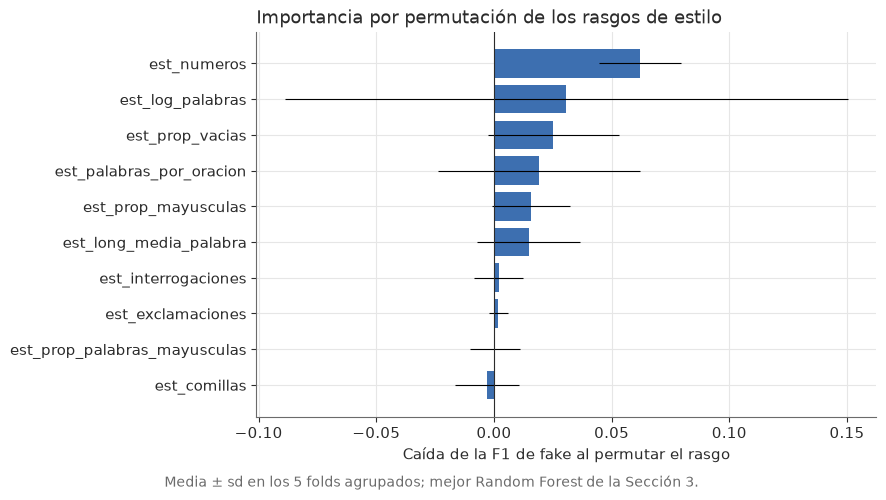

,mean,std
est_numeros,0.0621,0.0176
est_log_palabras,0.0308,0.1197
est_prop_vacias,0.0253,0.0278
est_palabras_por_oracion,0.0192,0.0430
est_prop_mayusculas,0.0157,0.0166
est_long_media_palabra,0.0148,0.0220
est_interrogaciones,0.0019,0.0106
est_exclamaciones,0.0019,0.0041
est_prop_palabras_mayusculas,0.0003,0.0107
est_comillas,-0.0029,0.0135


In [8]:
importancias = []
for k in sorted(corpus['fold_grupo'].unique()):
    entrenamiento, validacion = corpus[corpus['fold_grupo'] != k], corpus[corpus['fold_grupo'] == k]
    modelo = uf.construir_modelo_estilo({'modelo': 'RF', 'parametros': mejor_rf}).fit(entrenamiento, entrenamiento['Category'])
    imp = permutation_importance(modelo, validacion[RASGOS], validacion['Category'], scoring = F1_FAKE, n_repeats = 20, random_state = SEMILLA, n_jobs = -1)
    importancias.append(pd.Series(imp.importances_mean, index = RASGOS, name = k))
tabla_imp = pd.concat(importancias, axis = 1).agg(['mean', 'std'], axis = 1).sort_values('mean')

fig, ax = plt.subplots(figsize = (8, 5))
ax.barh(tabla_imp.index, tabla_imp['mean'], xerr = tabla_imp['std'], color = '#3D6FB0', error_kw = {'lw': 0.8})
ax.axvline(0, color = TINTA, linewidth = 0.8)
ax.set_xlabel('Caída de la F1 de fake al permutar el rasgo')
ax.set_title('Importancia por permutación de los rasgos de estilo')
fig.text(0.01, -0.03, 'Media ± sd en los 5 folds agrupados; mejor Random Forest de la Sección 3.', color = TINTA_SUAVE, fontsize = 10)
guardar(fig, '4_1_importancia_rasgos')
plt.show()
tabla_imp.sort_values('mean', ascending = False).round(4)

**Qué se observa.** El rasgo más importante es `est_numeros` (la F1 cae 0.062 ± 0.018 al permutarlo), el único que conserva su dirección entre versiones (preparación, Tabla 5.2). Le siguen la longitud (0.031, pero con sd de 0.120: importa mucho en unos folds y nada en otros) y la proporción de palabras vacías (0.025). Exclamaciones, interrogaciones, mayúsculas sostenidas y comillas tienen importancia cercana a 0 o negativa. **Los signos "sensacionalistas" no sirven en este corpus; lo que distingue es cuántos datos numéricos cita la noticia y su longitud.**

<a id="seccion-5"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 5: Diagnóstico: folds aleatorios</span></div>

> **Qué se hace:** evaluamos el mejor bosque y la mejor regresión sobre rasgos con folds aleatorios.
>
> **Qué se espera ver:** una subida menor que la de los modelos de texto, porque 10 rasgos de estilo identifican peor al medio que el vocabulario.

⚠️ No se usa para elegir.

**Tabla 5.1.** F1 de fake con folds agrupados y aleatorios.

In [9]:
mejor_c = float(uf.resumir_cv(cv_lr_estilo).index[0].split('=')[1])
modelos_diag = {'RF': {'modelo': 'RF', 'parametros': mejor_rf}, 'LR sobre rasgos': {'modelo': 'LR', 'parametros': {'C': mejor_c}}}
filas = []
for esquema in ['fold_grupo', 'fold_aleatorio']:
    cv_e = uf.evaluar_por_folds(corpus, esquema, lambda e, v: {n: uf.construir_modelo_estilo(c).fit(e, e['Category']).predict(v) for n, c in modelos_diag.items()})
    filas.append(cv_e.assign(esquema = esquema))
cv_diag = pd.concat(filas, ignore_index = True)
tabla5 = cv_diag.groupby(['config', 'esquema'])['F1_fake'].mean().unstack()
tabla5['aleatorio − agrupado'] = tabla5['fold_aleatorio'] - tabla5['fold_grupo']
tabla5.round(3)

esquema,fold_aleatorio,fold_grupo,aleatorio − agrupado
config,,,
LR sobre rasgos,0.757,0.672,0.085
RF,0.768,0.626,0.142


**Qué se observa.** Con folds aleatorios, el bosque sube de 0.626 a 0.768 (+0.142) y la regresión sobre rasgos de 0.672 a 0.757 (+0.085). La subida del bosque es mayor que la de los modelos de texto (+0.09 a +0.11). **El bosque usa los rasgos para reconocer medios (la longitud y el estilo de cada sitio) más que para detectar falsedad; por eso cae tanto cuando el medio es nuevo.**

<a id="seccion-6"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 6: Comparación con el modelo de texto</span></div>

> **Qué se hace:** comparamos fold por fold el mejor bosque con el modelo de texto elegido en `modelos_lineales.ipynb`.
>
> **Qué se espera ver:** que el modelo de texto sea mejor en la mayoría de los folds.

Reentrenamos el modelo de texto con su configuración guardada para tener sus predicciones por fold. **Tabla 6.1.** F1 de fake por fold y diferencia (bosque − texto).

In [10]:
with open(os.path.join(uf.RUTA_RESULTADOS, 'seleccion_lineal.json'), encoding = 'utf-8') as f:
    config_texto = json.load(f)['elegida']
cv_texto = uf.evaluar_por_folds(corpus, 'fold_grupo', lambda e, v: {'texto': uf.construir_pipeline(config_texto).fit(e, e['Category']).predict(v)})
comparacion = pd.DataFrame({'Random Forest (estilo)': cv_rf[cv_rf['config'] == resumen_rf.index[0]].set_index('fold')['F1_fake'],
                            'LR (texto, elegido)': cv_texto.set_index('fold')['F1_fake']})
comparacion['diferencia'] = comparacion['Random Forest (estilo)'] - comparacion['LR (texto, elegido)']
resumen_comp = pd.DataFrame({'Random Forest (estilo)': [comparacion['Random Forest (estilo)'].mean()], 'LR (texto, elegido)': [comparacion['LR (texto, elegido)'].mean()],
                             'diferencia': [f"{comparacion['diferencia'].mean():.3f} ± {comparacion['diferencia'].std():.3f}; gana el bosque en {int((comparacion['diferencia'] > 0).sum())} de 5"]},
                            index = ['media'])
pd.concat([comparacion.round(3), resumen_comp])

,Random Forest (estilo),"LR (texto, elegido)",diferencia
0,0.690000,0.785000,-0.095
1,0.425000,0.854000,-0.429
2,0.692000,0.634000,0.057
3,0.588000,0.638000,-0.049
4,0.737000,0.738000,-0.001
media,0.626243,0.729788,-0.104 ± 0.191; gana el bosque en 1 de 5


**Qué se observa.** El modelo de texto gana en 4 de 5 folds. La diferencia media es −0.104 ± 0.191 (bosque − texto), y el peor caso es el fold 1, donde el bosque obtiene 0.425 contra 0.854. **El modelo de estilo no compite con el de texto como sistema principal.**

¿Fallan en las mismas noticias? Si los errores no coinciden, una combinación podría ayudar (el overview encontró complementariedad entre enfoques). **Tabla 6.2.** Acuerdo de los aciertos de ambos modelos en las predicciones de validación (5 folds juntos).

In [11]:
def aciertos(funcion):
    '''
    Función que junta las predicciones de validación de los 5 folds y marca los aciertos

    inputs:
    --------
        funcion (callable): Recibe (entrenamiento, validacion) y devuelve las predicciones de validación

    outputs:
    --------
        pandas.Series: True si la noticia se clasificó bien, indexada por id_unico
    '''
    partes = []
    for k in sorted(corpus['fold_grupo'].unique()):
        e, v = corpus[corpus['fold_grupo'] != k], corpus[corpus['fold_grupo'] == k]
        partes.append(pd.Series(funcion(e, v) == v['Category'].values, index = v['id_unico']))
    return pd.concat(partes)

acierto_rf = aciertos(lambda e, v: uf.construir_modelo_estilo({'modelo': 'RF', 'parametros': mejor_rf}).fit(e, e['Category']).predict(v))
acierto_texto = aciertos(lambda e, v: uf.construir_pipeline(config_texto).fit(e, e['Category']).predict(v))
pd.crosstab(acierto_rf.rename('acierta el bosque'), acierto_texto.rename('acierta el modelo de texto'), margins = True)

acierta el modelo de texto,False,True,All
acierta el bosque,,,
False,147,173,320
True,86,555,641
All,233,728,961


**Qué se observa.** En validación, el modelo de texto acierta 728 de 961 noticias y el bosque, 641. En 86 noticias acierta solo el bosque, en 173 solo el texto y en 147 fallan los dos. **Los errores se solapan en parte, pero no del todo: un oráculo que eligiera el acierto de cualquiera de los dos llegaría a 814 de 961 (84.7 %). Hay algo de complementariedad, como encontró el overview, aunque un ensamble práctico necesitaría saber cuándo confiar en cada uno; queda como siguiente paso.**

<a id="seccion-7"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 7: Selección y guardado</span></div>

> **Qué se hace:** elegimos la configuración del bosque con la regla de un error estándar (la más simple dentro de un SE de la mejor) y guardamos todo.
>
> **Qué se espera ver:** un bosque poco profundo si la diferencia con el mejor es menor que un SE.

Simplicidad: menor profundidad (sin límite cuenta como la mayor), luego hojas más grandes y luego `sqrt`. **Tabla 7.1.** Configuración elegida.

In [12]:
umbral = resumen_rf.iloc[0]['F1_fake_mean'] - resumen_rf.iloc[0]['F1_fake_se']
cand = resumen_rf[resumen_rf['F1_fake_mean'] >= umbral].copy()
cand['params'] = [json.loads(i) for i in cand.index]
cand['profundidad'] = [p['max_depth'] if p['max_depth'] is not None else 99 for p in cand['params']]
cand['hoja'] = [-p['min_samples_leaf'] for p in cand['params']]
cand['atributos'] = [0 if p['max_features'] == 'sqrt' else 1 for p in cand['params']]
elegida_rf = cand.sort_values(['profundidad', 'hoja', 'atributos']).iloc[0]
seleccion_arboles = {'elegida': {'modelo': 'RF', 'parametros': elegida_rf['params']},
                     'cv_elegida': {c: float(elegida_rf[c]) for c in ['F1_fake_mean', 'F1_fake_std', 'F1_macro_mean', 'accuracy_mean']},
                     'mejor_media': {'modelo': 'RF', 'parametros': mejor_rf},
                     'lr_estilo': {'modelo': 'LR', 'parametros': {'C': mejor_c}},
                     'regla': 'un error estándar; menor profundidad, hojas más grandes, sqrt', 'semilla': SEMILLA, 'n_arboles': N_ARBOLES}
with open(os.path.join(uf.RUTA_RESULTADOS, 'seleccion_arboles.json'), 'w', encoding = 'utf-8') as f:
    json.dump(seleccion_arboles, f, ensure_ascii = False, indent = 1)
print(f'{len(cand)} combinaciones dentro de un SE (umbral = {umbral:.3f})')
pd.Series({**{k: str(v) for k, v in elegida_rf['params'].items()}, 'F1 fake (CV)': f"{elegida_rf['F1_fake_mean']:.3f} ± {elegida_rf['F1_fake_std']:.3f}",
           'macro-F1 (CV)': f"{elegida_rf['F1_macro_mean']:.3f}"}, name = 'valor').to_frame()

24 combinaciones dentro de un SE (umbral = 0.570)


,valor
max_depth,3
max_features,sqrt
min_samples_leaf,20
F1 fake (CV),0.608 ± 0.168
macro-F1 (CV),0.647


**Qué se observa.** Las 24 combinaciones están dentro de un SE (umbral 0.570). La regla elige la más simple: árboles de profundidad 3, `sqrt` y hojas de 20, con 0.608 ± 0.168. Está 0.018 por debajo de la mejor media, dentro de la incertidumbre, y es mucho más interpretable. **Se lleva al test como sistema secundario de referencia; el principal sigue siendo el modelo de texto.**

**Tabla 7.2.** Filas de `resultados/cv_arboles.csv` por etapa (formato común).

In [13]:
def formato(cv, modelo, etapa, esquema = 'fold_grupo'):
    '''
    Función que lleva resultados de evaluar_por_folds al formato común de los CSV de CV

    inputs:
    --------
        cv (pandas.DataFrame): Resultados por fold
        modelo (str): Nombre del modelo
        etapa (str): Nombre de la etapa
        esquema (str): Columna de folds usada

    outputs:
    --------
        pandas.DataFrame: Columnas del formato común
    '''
    return pd.DataFrame({'modelo': modelo, 'representación': '10 rasgos de estilo', 'hiperparámetros': cv['config'], 'fold': cv['fold'],
                         'F1_fake': cv['F1_fake'], 'F1_macro': cv['F1_macro'], 'accuracy': cv['accuracy'], 'F1_true': cv['F1_true'],
                         'esquema': cv.get('esquema', esquema), 'etapa': etapa})

cv_arboles = pd.concat([formato(cv_lr_estilo, 'LR', 'referencia lineal'), formato(cv_rf, 'RF', 'rejilla'),
                        formato(cv_diag, 'diagnóstico', 'diagnóstico folds')], ignore_index = True)
guardar_csv(cv_arboles, 'cv_arboles')
cv_arboles.groupby('etapa', sort = False).size().rename('filas').to_frame()

,filas
etapa,
referencia lineal,20
rejilla,120
diagnóstico folds,20


<a id="conclusiones"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conclusiones</span></div>

<a id="seccion-8"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 8: Resumen por sección</span></div>

> **Qué se hace:** reunimos los resultados.
>
> **Qué se espera ver:** el papel del modelo de estilo frente al de texto.

**Tabla 8.1.** Resumen por sección (F1 de fake en CV agrupada).

| Sección | Qué se hizo | Hallazgo principal | Salidas |
|:--|:--|:--|:--|
| 2. Referencia lineal | LR sobre 10 rasgos escalados | 0.672 ± 0.094; C casi no importa | Tabla 2.1 |
| 3. Random Forest | Rejilla de 24 combinaciones | Mejor: 0.626 ± 0.125, por debajo de la LR sobre rasgos | `cv_arboles.csv` |
| 4. Importancia | Permutación en validación | Dominan los números citados (0.062) y la longitud; los signos no importan | Figura 4.1 |
| 5. Diagnóstico | Folds aleatorios | El bosque sube +0.142: reconoce medios | Tabla 5.1 |
| 6. Comparación | Frente al modelo de texto | El texto gana en 4 de 5 folds (−0.104 ± 0.191); 86 noticias las acierta solo el bosque | Tablas 6.1 y 6.2 |
| 7. Selección | Regla de un SE, la más simple | Profundidad 3, hojas de 20: 0.608 ± 0.168 | `seleccion_arboles.json` |


<a id="seccion-9"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 9: Implicaciones para la evaluación</span></div>

> **Qué se hace:** listamos qué se lleva a `evaluacion.ipynb`.
>
> **Qué se espera ver:** sistemas secundarios y análisis.

* El Random Forest elegido (profundidad 3, hojas de 20) se evalúa en el test **solo como sistema secundario**.
* Esperamos que caiga en el test: depende de rasgos que se comportan distinto entre versiones y de reconocer medios.
* La complementariedad (86 noticias acertadas solo por el bosque) justifica dejar planeado un ensamble con pesos aprendidos en CV, junto con el transformer (`notas/siguientes_pasos.md`).


<a id="seccion-10"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 10: Referencias</span></div>

> **Qué se hace:** fuentes citadas.
>
> **Qué se espera ver:** referencias completas.

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32.
2. Gamallo, P. (2021). CiTIUS at FakeDeS 2021: A Hybrid Strategy for Fake News Detection. *CEUR-WS* Vol. 2943, 609–614 (heurísticas de longitud y mayúsculas).
3. Gómez-Adorno, H., Posadas-Durán, J. P., Bel Enguix, G. y Porto Capetillo, C. (2021). Overview of FakeDeS at IberLEF 2021. *Procesamiento del Lenguaje Natural*, 67, 223–231.
4. Hastie, T., Tibshirani, R. y Friedman, J. (2009). *The Elements of Statistical Learning* (2.ª ed.). Springer. Sección 7.10.
5. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR*, 12, 2825–2830 (`permutation_importance`).